In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/raw/chennai_house_price_prediction.csv')

## 1. Data quality audit

In [10]:
# Missing value analysis
missing_report = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': df.isnull().mean() * 100,
    "data_type": df.dtypes
}
)

missing_report = missing_report.sort_values(
    "Missing Percentage",
    ascending=False
)
missing_report

,Missing Values,Missing Percentage,data_type
QS_OVERALL,48,0.675200,float64
N_BATHROOM,5,0.070333,float64
N_BEDROOM,1,0.014067,float64
INT_SQFT,0,0.000000,int64
AREA,0,0.000000,str
PRT_ID,0,0.000000,str
DIST_MAINROAD,0,0.000000,int64
SALE_COND,0,0.000000,str
PARK_FACIL,0,0.000000,str
BUILDTYPE,0,0.000000,str


In [11]:
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0])

N_BEDROOM      1
N_BATHROOM     5
QS_OVERALL    48
dtype: int64


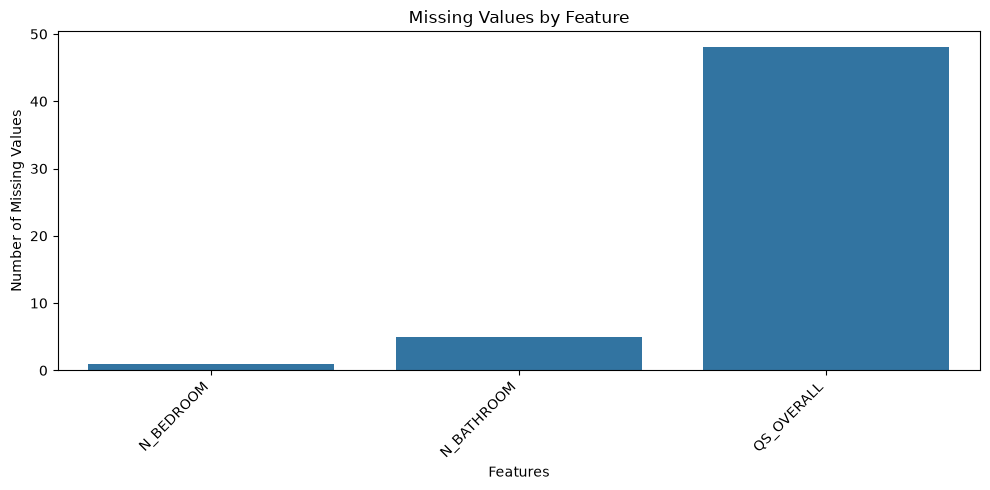

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

if not missing_counts.empty:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=missing_counts.index,
        y=missing_counts.values
    )

    plt.title("Missing Values by Feature")
    plt.xlabel("Features")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found!")

In [13]:
df.dtypes

PRT_ID               str
AREA                 str
INT_SQFT           int64
DIST_MAINROAD      int64
N_BEDROOM        float64
N_BATHROOM       float64
N_ROOM             int64
SALE_COND            str
PARK_FACIL           str
BUILDTYPE            str
UTILITY_AVAIL        str
STREET               str
MZZONE               str
QS_ROOMS         float64
QS_BATHROOM      float64
QS_BEDROOM       float64
QS_OVERALL       float64
COMMIS             int64
SALES_PRICE        int64
dtype: object

In [14]:
df['AREA'].value_counts()

AREA
Chrompet      1681
Karapakkam    1363
KK Nagar       996
Velachery      979
Anna Nagar     783
Adyar          773
T Nagar        496
Chrompt          9
Chrmpet          6
Chormpet         6
TNagar           5
Karapakam        3
Ana Nagar        3
Velchery         2
Ann Nagar        2
Adyr             1
KKNagar          1
Name: count, dtype: int64

In [15]:
categorical_cols = [
    "AREA", "SALE_COND", "PARK_FACIL",
    "BUILDTYPE", "UTILITY_AVAIL", "STREET", "MZZONE"
]

for col in categorical_cols:
    print(f"\nValue counts for {col}")

    counts = df[col].value_counts().reset_index()
    counts.columns = [col, "COUNT"]

    display(counts)


Value counts for AREA


,AREA,COUNT
0,Chrompet,1681
1,Karapakkam,1363
2,KK Nagar,996
3,Velachery,979
4,Anna Nagar,783
5,Adyar,773
6,T Nagar,496
7,Chrompt,9
8,Chrmpet,6
9,Chormpet,6



Value counts for SALE_COND


,SALE_COND,COUNT
0,AdjLand,1433
1,Partial,1429
2,Normal Sale,1423
3,AbNormal,1406
4,Family,1403
5,Adj Land,6
6,Ab Normal,5
7,Partiall,3
8,PartiaLl,1



Value counts for PARK_FACIL


...

,UTILITY_AVAIL,COUNT
0,AllPub,1886
1,NoSeWa,1871
2,NoSewr,1829
3,ELO,1522
4,All Pub,1



Value counts for STREET


,STREET,COUNT
0,Paved,2560
1,Gravel,2520
2,No Access,2010
3,Pavd,12
4,NoAccess,7



Value counts for MZZONE


,MZZONE,COUNT
0,RL,1858
1,RH,1822
2,RM,1817
3,C,550
4,A,537
5,I,525


### Categorical Feature Analysis: Conclusion

The categorical feature analysis of the Chennai House Price Prediction dataset revealed several inconsistencies in category labels.

- **AREA:** Multiple spelling variations exist for location names, potentially causing the same location to be treated as separate categories.
- **SALE_COND:** Several labels contain spelling or formatting variations.
- **PARK_FACIL:** The dataset contains two occurrences of `Noo`, which may represent `No`.
- **BUILDTYPE:** Variations such as `Other`/`Others` and `Comercial`/`Commercial` require validation.
- **UTILITY_AVAIL:** A possible formatting inconsistency exists between `All Pub` and `AllPub`.
- **STREET:** Variations such as `Pavd`/`Paved` and `NoAccess`/`No Access` were identified.
- **MZZONE:** Six distinct categories were observed without obvious spelling inconsistencies in the frequency table.

**Conclusion:** The categorical features require a data-quality check before model training. Verified spelling and formatting errors should be standardized to prevent equivalent categories from being encoded separately. Valid categories must be preserved, and the relationships between categorical features and `SALES_PRICE` should be examined in subsequent analysis.

# 2. Target variable analysis

In [20]:
target = "SALES_PRICE"

display(df[target].describe().to_frame().map(lambda x: f'{x:,.2f}'))

print("Mean:", df[target].mean())
print("Median:", df[target].median())
print("Skewness:", df[target].skew())
print("Kurtosis:", df[target].kurtosis())

,SALES_PRICE
count,"7,109.00"
mean,"10,894,909.64"
std,"3,768,603.46"
min,"2,156,875.00"
25%,"8,272,100.00"
50%,"10,335,050.00"
75%,"12,993,900.00"
max,"23,667,340.00"


Mean: 10894909.63918976
Median: 10335050.0
Skewness: 0.7733433358864339
Kurtosis: 0.5881293416070832


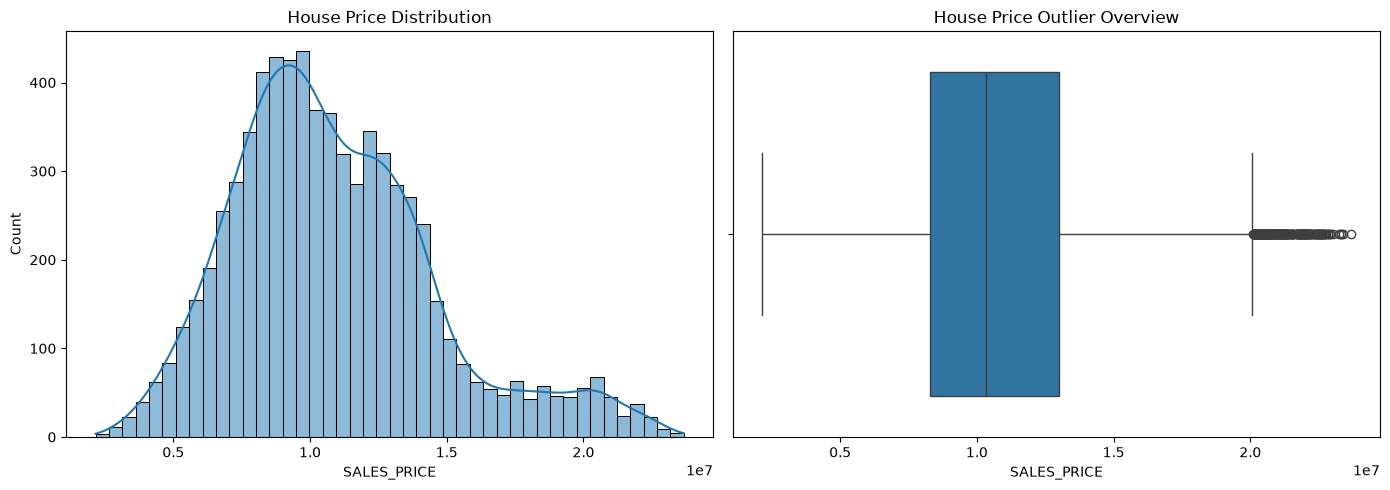

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="SALES_PRICE",
    kde=True,
    ax=axes[0]
)

axes[0].set_title("House Price Distribution")

sns.boxplot(
    data=df,
    x="SALES_PRICE",
    ax=axes[1]
)

axes[1].set_title("House Price Outlier Overview")

plt.tight_layout()
plt.show()

## 3. Univarient Analysis

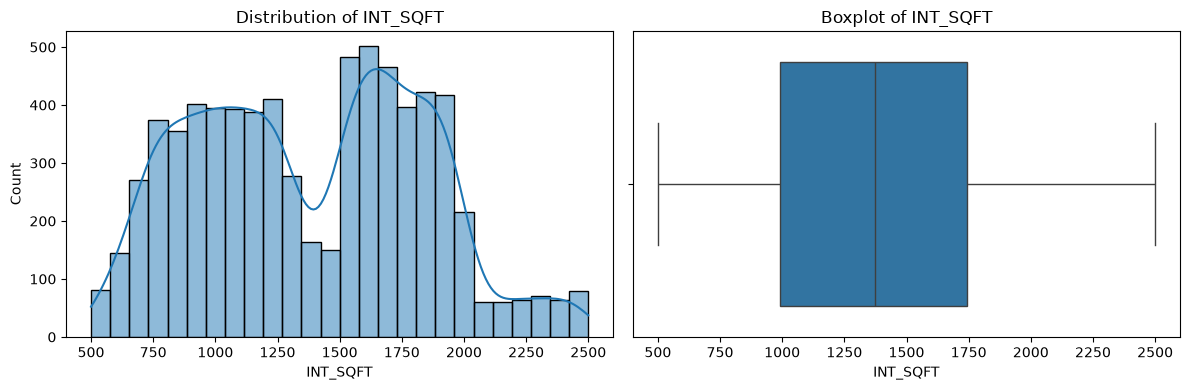

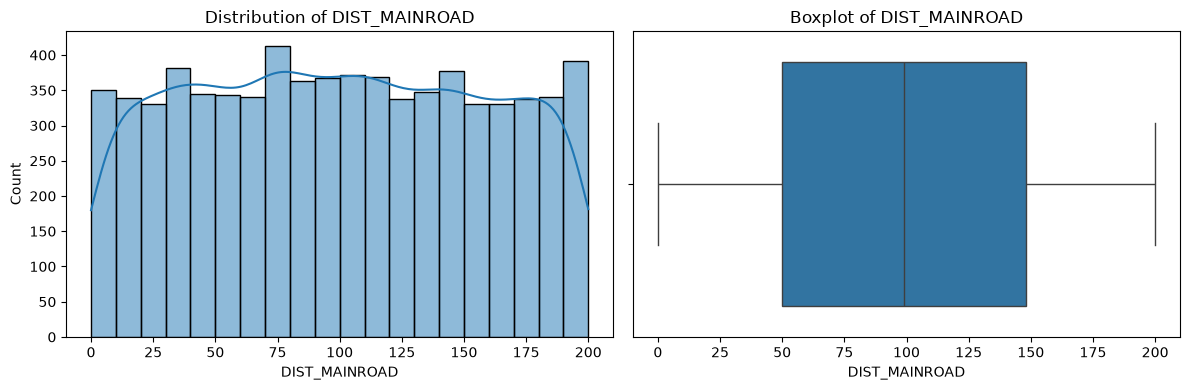

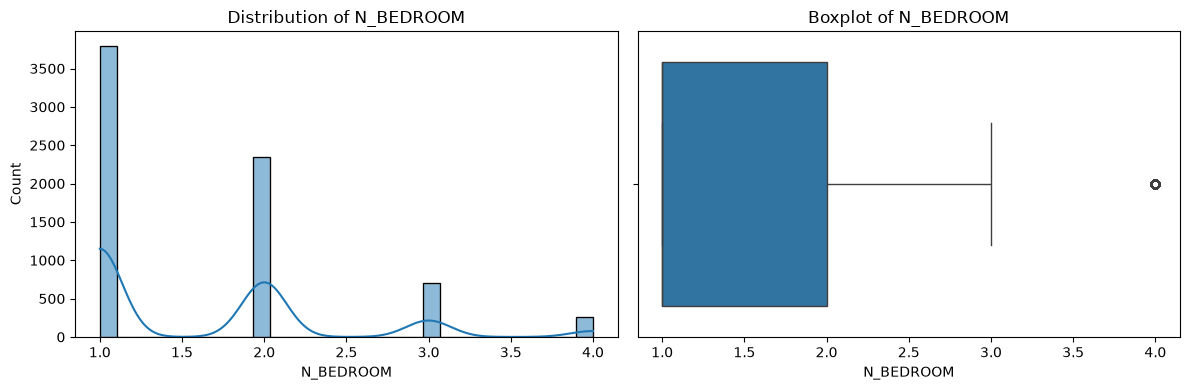

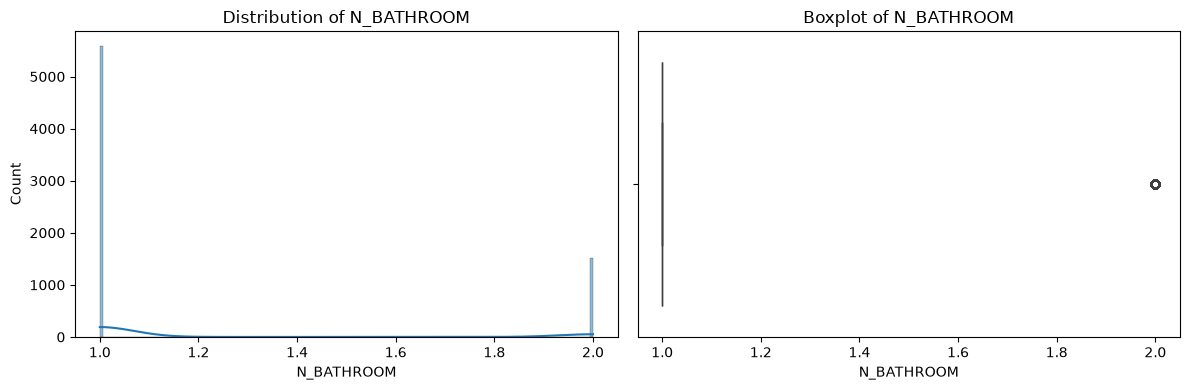

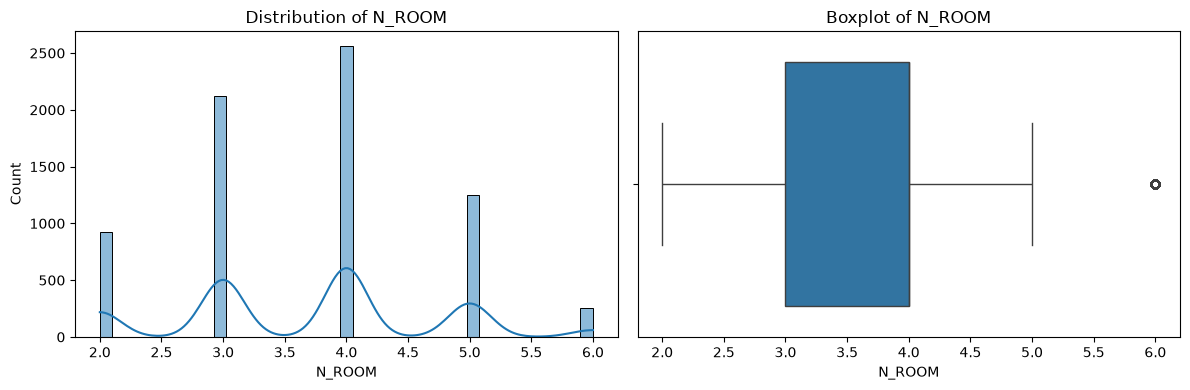

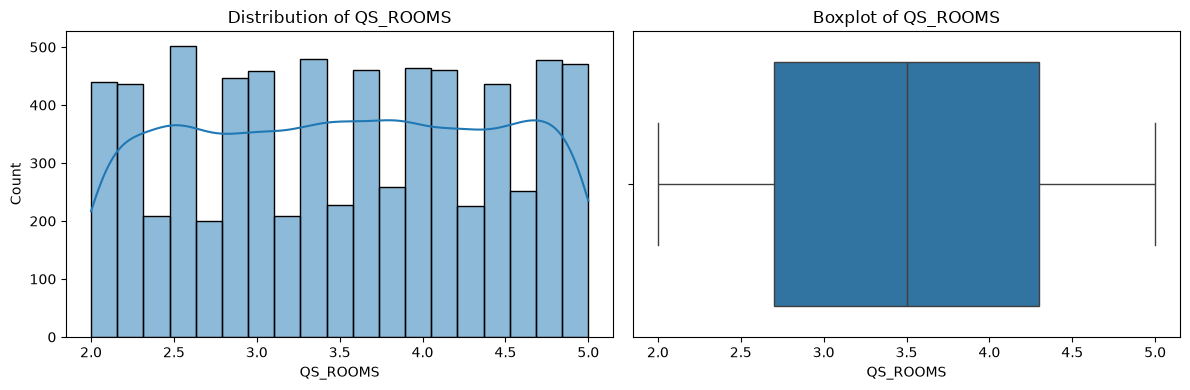

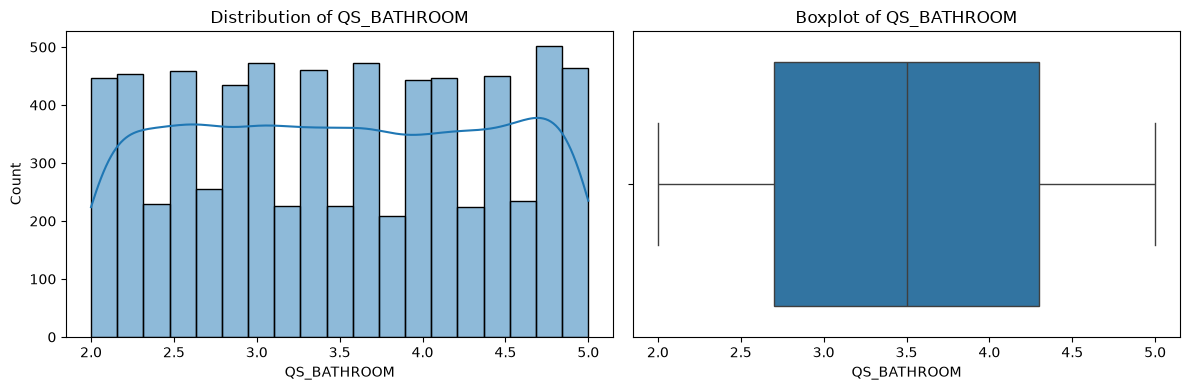

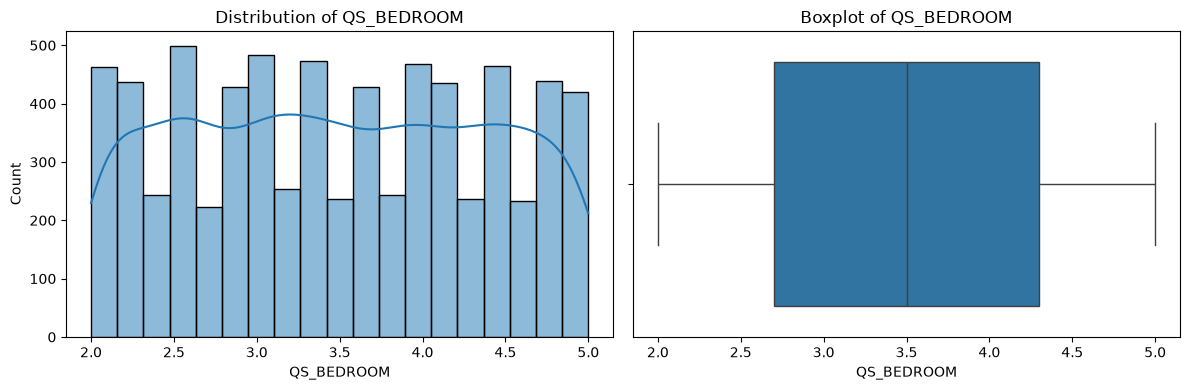

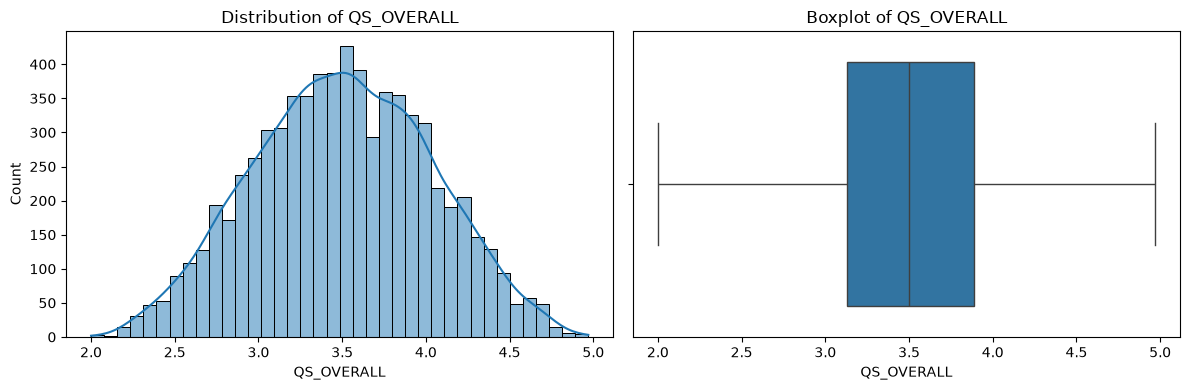

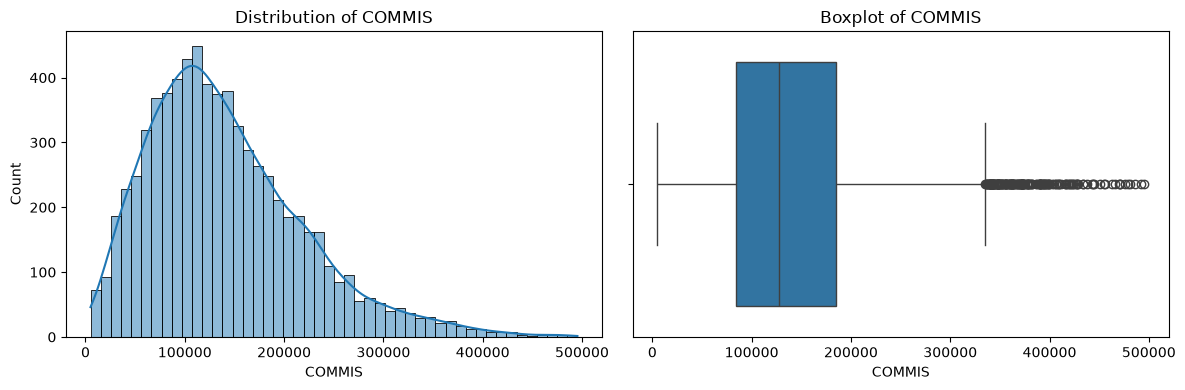

In [24]:
# 12. Numerical Feature Distributions
numerical_cols = df.select_dtypes(
    include=np.number
).columns



features_to_plot = [
    col for col in numerical_cols
    if col != target
]

for col in features_to_plot:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(f"Distribution of {col}")

    sns.boxplot(
        data=df,
        x=col,
        ax=axes[1]
    )

    axes[1].set_title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()

In [33]:
# 14. Categorical Value Counts

for col in categorical_cols:
    print('\n')
    print(f"Feature: {col}")
    

    display(
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="Count")
    )



Feature: AREA


,AREA,Count
0,Chrompet,1681
1,Karapakkam,1363
2,KK Nagar,996
3,Velachery,979
4,Anna Nagar,783
5,Adyar,773
6,T Nagar,496
7,Chrompt,9
8,Chrmpet,6
9,Chormpet,6




Feature: SALE_COND


,SALE_COND,Count
0,AdjLand,1433
1,Partial,1429
2,Normal Sale,1423
3,AbNormal,1406
4,Family,1403
5,Adj Land,6
6,Ab Normal,5
7,Partiall,3
8,PartiaLl,1




Feature: PARK_FACIL


...

,UTILITY_AVAIL,Count
0,AllPub,1886
1,NoSeWa,1871
2,NoSewr,1829
3,ELO,1522
4,All Pub,1




Feature: STREET


,STREET,Count
0,Paved,2560
1,Gravel,2520
2,No Access,2010
3,Pavd,12
4,NoAccess,7




Feature: MZZONE


,MZZONE,Count
0,RL,1858
1,RH,1822
2,RM,1817
3,C,550
4,A,537
5,I,525


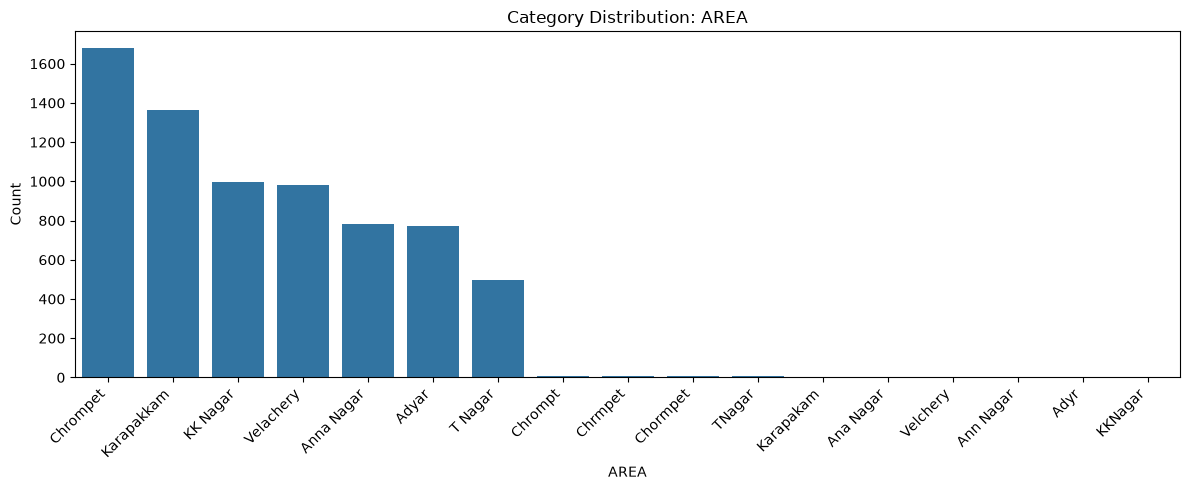

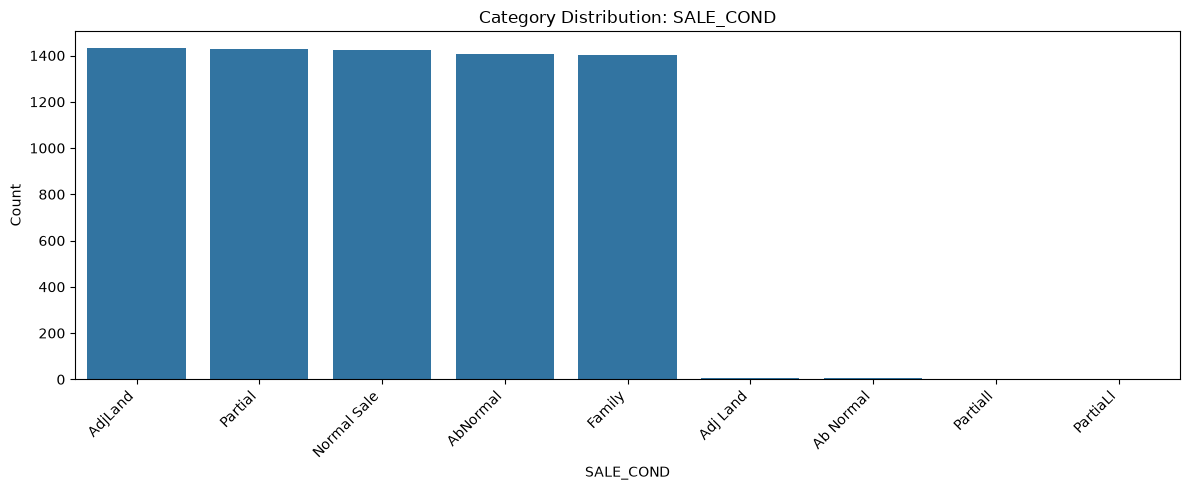

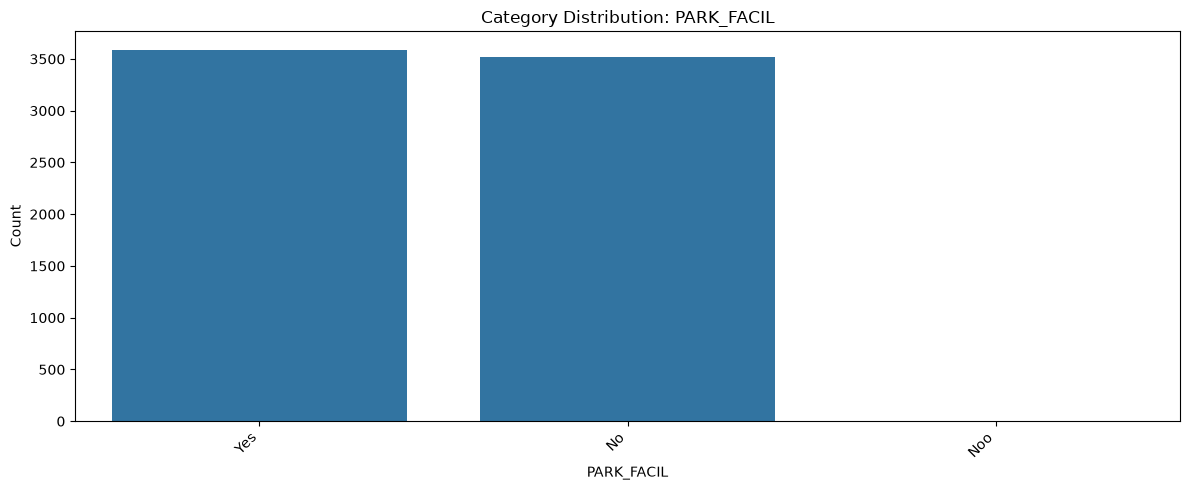

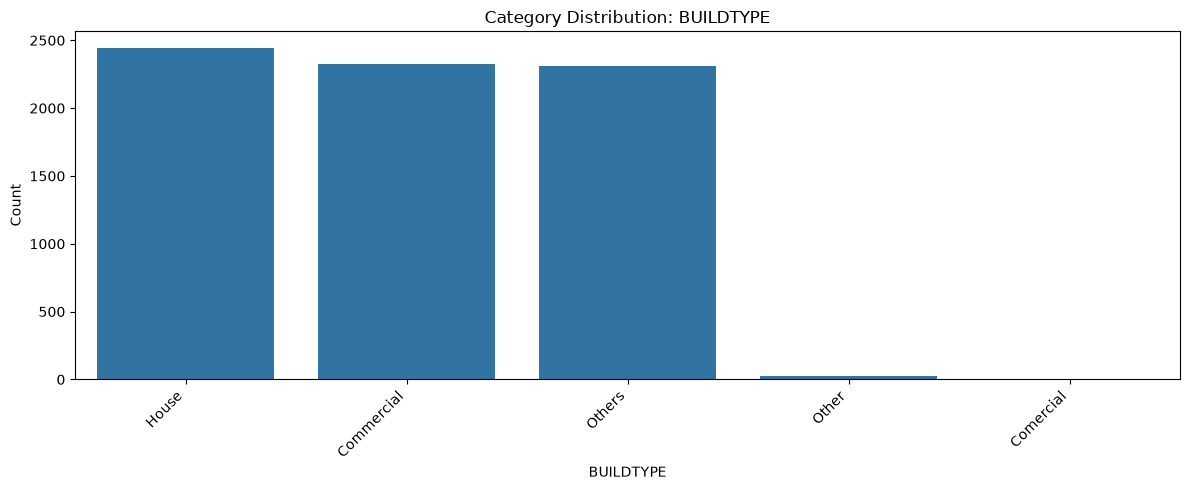

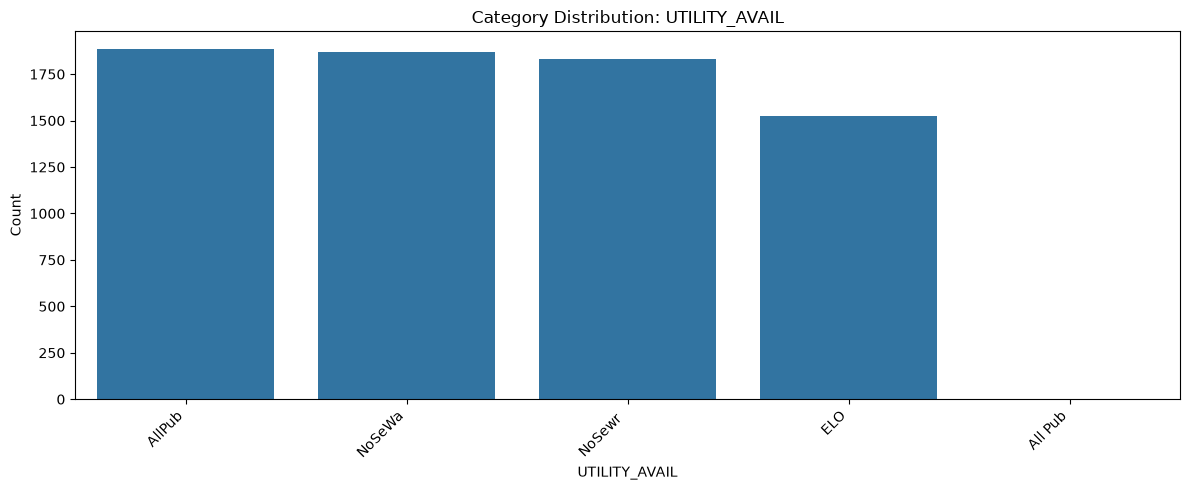

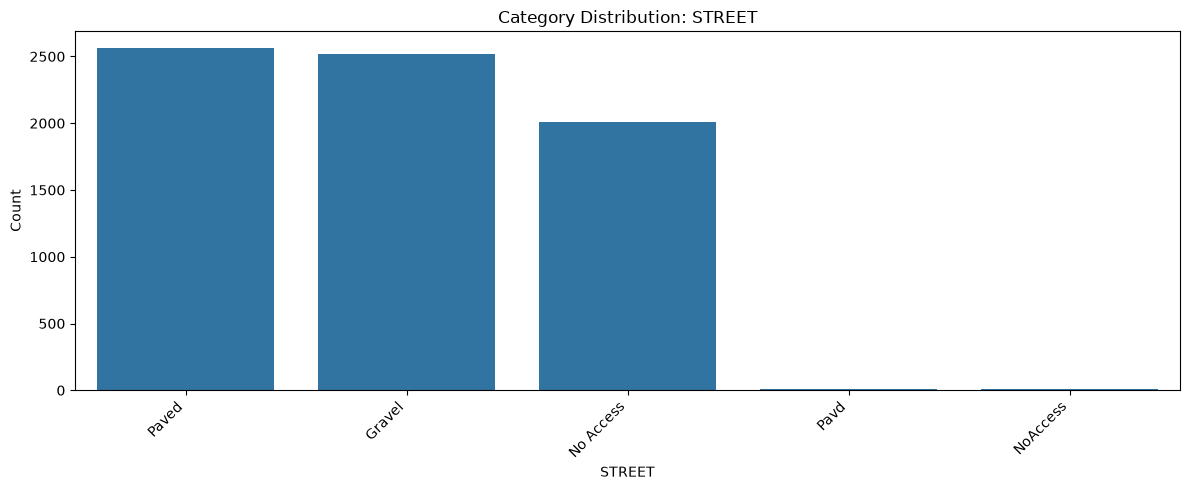

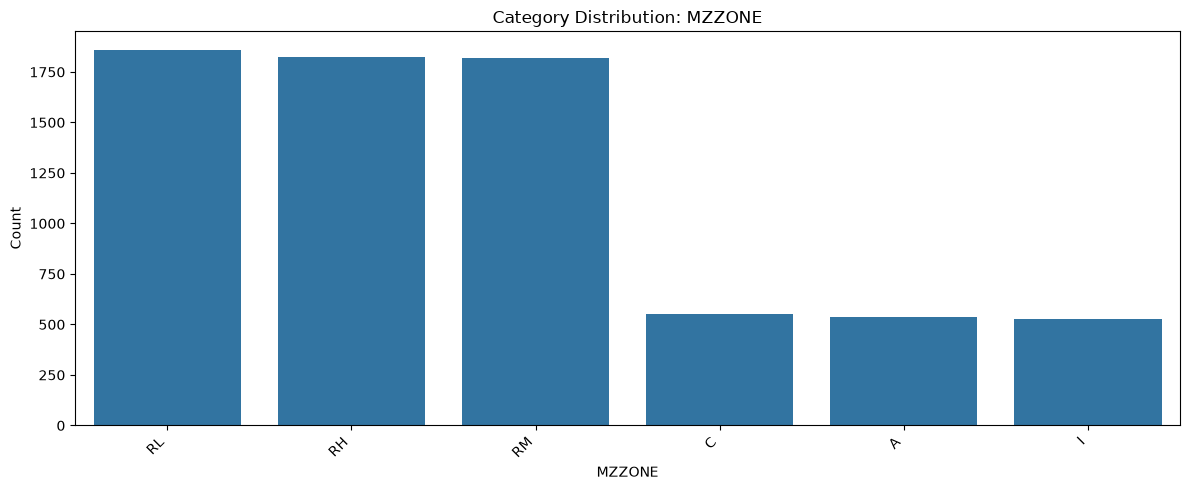

In [28]:
# 13. Categorical Feature Distributions

for col in categorical_cols:
    plt.figure(figsize=(12, 5))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order
    )

    plt.title(f"Category Distribution: {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


<Axes: >

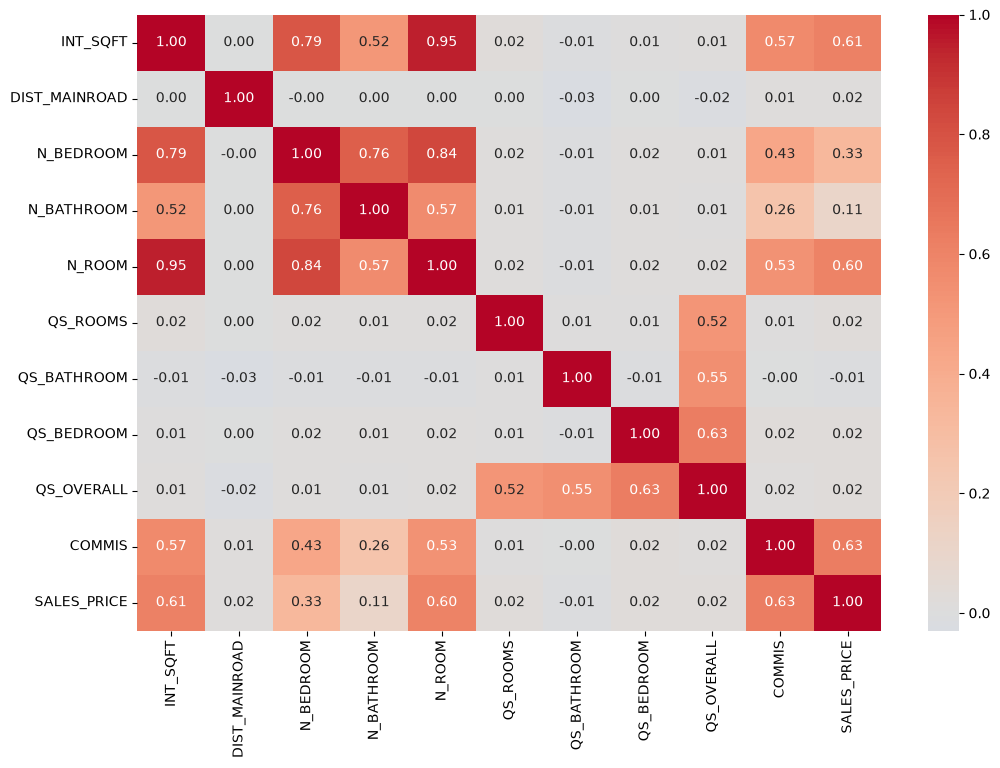

In [35]:
# 15. Numerical Correlation Analysis

correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

In [36]:
# 16. Correlation with Target

target_correlation = (
    correlation_matrix[target]
    .drop(target)
    .sort_values(ascending=False)
)

display(
    target_correlation.to_frame(
        name="Correlation with Sales Price"
    )
)


,Correlation with Sales Price
COMMIS,0.626275
INT_SQFT,0.612125
N_ROOM,0.602760
N_BEDROOM,0.330999
N_BATHROOM,0.108884
QS_ROOMS,0.021967
QS_OVERALL,0.020556
QS_BEDROOM,0.018804
DIST_MAINROAD,0.018783
QS_BATHROOM,-0.011377
